# What passes from a reinforcement-learning teacher to a distilled student?

Code for the research report of the same title by Jeffrey Mamabolo (School of Computer Science and Applied Mathematics, University of the Witwatersrand).

The model has two stages. In stage 1 an RL perceptron learns a rule $w^*$ from sparse, delayed rewards (Patel et al. 2025). In stage 2 a frozen copy of that perceptron teaches a two-layer student by online gradient descent (Lee et al. 2022). Equation numbers refer to the report. A full run takes 20 to 30 minutes on a laptop and needs NumPy, SciPy and Matplotlib.

Every building block is checked before it is used, and every claim of the report is checked where it is made:

1. equations (2) and (3) against sampled fields;
2. the stage-1 runs against equation (4);
3. the trained RL perceptron against 50,000 played episodes;
4. the three Gaussian integrals against sampled fields;
5. the covariance assembler against measured field covariances;
6. the error formula against sampled fields and the perfect-copy limit;
7. one step of student training against the gradient of the loss;
8. the stage-2 runs against equation (7);
9. the sweep: every teacher is copied equally well;
10. $U=\rho R$, in the equations and in the simulations;
11. the teacher's decisions on the sampled fields against equation (2);
12. the student's reward from its overlaps against 40,000 played episodes;
13. the student earns its teacher's reward, for every teacher;
14. equation (9) against the exact reward;
15. teachers trained with other episode lengths: only $\rho$ passes.

The numbers quoted in the report are collected in `results` along the way and listed in the summary at the end, next to the values in the report.

- Patel N, Lee S, Sarao Mannelli S, Goldt S and Saxe A 2025 RL perceptron: generalization dynamics of policy learning in high dimensions *Phys. Rev. X* **15** 021051
- Lee S, Sarao Mannelli S, Clopath C, Goldt S and Saxe A 2022 Maslow's hammer in catastrophic forgetting: node re-use vs. node activation *ICML 2022* (arXiv:2205.09029)

## Setup

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.interpolate import interp1d
from scipy.special import erf, erfc, erfinv

# settings (table 1 of the report)
D = 1000                # input dimension
T = 5                   # episode length
K = 2                   # hidden units of the student
ETA = 0.1               # student learning rate, both layers
ALPHA_RL = 500          # stage-1 training time, in episodes / D
ALPHA_STUDENT = 3000    # stage-2 training time of the main run, in steps / D
ALPHA_SWEEP = 300       # stage-2 training time of each student in the sweep
N_RUNS = 5              # independent runs
SWEEP_RHOS = [0.2, 0.4, 0.6, 0.8, 0.9, 0.95]   # teacher qualities at which copies are frozen

# figure style: simulation in colour underneath, theory in black dashes on top
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 14, "axes.labelsize": 15, "legend.fontsize": 12.5,
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "legend.frameon": False, "axes.grid": True, "grid.alpha": 0.25,
    "pdf.fonttype": 42, "savefig.bbox": "tight",
})
GREEN = "tab:green"
DASHES = [(0, (6, 2)), (0, (1, 1.4)), (0, (4, 1.5, 1, 1.5))]
rho_colour = plt.cm.viridis
THEORY = dict(color="black", lw=1.3, zorder=3)

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)


def label_panels(axes):
    for ax, letter in zip(axes, "abcde"):
        ax.annotate(f"({letter})", xy=(0, 1), xycoords="axes fraction", xytext=(-58, 10),
                    textcoords="offset points", fontweight="bold")


def rho_colourbar(fig, ax):
    scale = plt.cm.ScalarMappable(norm=plt.Normalize(0, 1), cmap=rho_colour)
    fig.colorbar(scale, ax=ax, label=r"teacher quality $\rho$")


def mean_sd(x):
    """Mean and standard deviation over the runs (first axis)."""
    x = np.asarray(x)
    return x.mean(axis=0), x.std(axis=0, ddof=1)

results = {}            # the numbers quoted in the report, collected along the way

## 1. Stage 1 — the RL perceptron

The perceptron makes $T$ decisions in an episode and is rewarded only if all of them agree with the rule $w^*$. Its overlaps $R = w\cdot w^*/D$ and $Q = w\cdot w/D$ follow equation (4), and its quality is $\rho = R/\sqrt{Q}$.

### The episodic training rule

In [2]:
class RLPerceptron:
    """Perceptron trained with the vanilla episodic rule of Patel et al.:
    reward 1 if all T decisions of an episode agree with the rule w*, else 0."""

    def __init__(self, D, T, seed, init_std=1e-3):
        self.D, self.T = D, T
        self.rng = np.random.default_rng(seed)
        w_star = self.rng.normal(size=D)
        self.w_star = w_star * np.sqrt(D) / np.linalg.norm(w_star)    # w*.w* = D exactly
        self.w = self.rng.normal(scale=init_std, size=D)
        self.frozen = {}

    def overlaps(self):
        Q = self.w @ self.w / self.D
        R = self.w @ self.w_star / self.D
        return Q, R, R / np.sqrt(Q)

    def episode(self):
        X = self.rng.normal(size=(self.T, self.D))
        y = np.sign(X @ self.w)
        rewarded = np.all(y == np.sign(X @ self.w_star))
        if rewarded:
            self.w += (y[:, None] * X).sum(axis=0) / (self.T * np.sqrt(self.D))
        return rewarded

    def train(self, n_episodes, record_every=500, freeze_at=()):
        """Returns the overlaps and the fraction of rewarded episodes, recorded every
        `record_every` episodes. A copy of w is kept at each episode count in `freeze_at`."""
        freeze_at = {int(n) for n in freeze_at}
        if 0 in freeze_at:
            self.frozen[0] = self.w.copy()
        history = {key: [] for key in ("alpha", "Q", "R", "rho", "reward")}
        rewarded = 0
        for n in range(1, n_episodes + 1):
            rewarded += self.episode()
            if n in freeze_at:
                self.frozen[n] = self.w.copy()
            if n % record_every == 0:
                values = (n / self.D, *self.overlaps(), rewarded / record_every)
                for key, value in zip(history, values):
                    history[key].append(value)
                rewarded = 0
        return {key: np.array(values) for key, values in history.items()}

### The theory: equations (2) to (4)

A perceptron of quality $\rho$ makes a wrong decision with probability $\arccos(\rho)/\pi$, so an episode is rewarded with probability $P^T$.

In [3]:
def rl_ode(T, alpha_max, Q0=1e-6, n_steps=20000):
    """Equation (4), solved with RK4 from R = 0. Returns alpha, R and Q."""
    def rhs(y):
        R, Q = y
        rho = R / np.sqrt(Q)
        P = 1 - np.arccos(rho) / np.pi
        dR = (1 + rho) * P ** (T - 1) / np.sqrt(2 * np.pi)
        dQ = np.sqrt(2 * Q / np.pi) * (1 + rho) * P ** (T - 1) + P ** T / T
        return np.array([dR, dQ])

    da = alpha_max / n_steps
    path = [np.array([0.0, Q0])]
    for _ in range(n_steps):
        y = path[-1]
        k1 = rhs(y); k2 = rhs(y + da / 2 * k1); k3 = rhs(y + da / 2 * k2); k4 = rhs(y + da * k3)
        path.append(y + da / 6 * (k1 + 2 * k2 + 2 * k3 + k4))
    R, Q = np.array(path).T
    return np.linspace(0, alpha_max, n_steps + 1), R, Q


def expected_reward_rl(rho, T=T):
    """Equation (3)."""
    return (1 - np.arccos(rho) / np.pi) ** T

### Check 1 — equations (2) and (3) against sampled fields

In [4]:
# the two fields of a decision are standard Gaussians with correlation rho
rho = 0.6
rng = np.random.default_rng(102)
fields = rng.normal(size=(1_000_000, 2)) @ np.linalg.cholesky(np.array([[1, rho], [rho, 1]])).T
agree = np.sign(fields[:, 0]) == np.sign(fields[:, 1])
print(f"wrong decisions:   {1 - agree.mean():.4f} sampled, {np.arccos(rho) / np.pi:.4f} from equation (2)")
print(f"rewarded episodes: {agree.reshape(-1, T).all(axis=1).mean():.4f} sampled, "
      f"{expected_reward_rl(rho):.4f} from equation (3)")

wrong decisions:   0.2956 sampled, 0.2952 from equation (2)
rewarded episodes: 0.1743 sampled, 0.1740 from equation (3)


### Solving equation (4)

The solution also fixes where copies of the perceptron will be frozen for the sweep of section 3: at the start, where equation (4) reaches each $\rho$ of the sweep, and at the end.

In [5]:
# solve equation (4), and choose when copies of the perceptron are frozen:
# at the start, where equation (4) reaches each rho of the sweep, and at the end
alpha_ode, R_ode, Q_ode = rl_ode(T, ALPHA_RL)
rho_ode = R_ode / np.sqrt(Q_ode)
reward_ode = expected_reward_rl(rho_ode)

FREEZE_ALPHAS = np.array([0.0] + [alpha_ode[np.argmax(rho_ode >= rho)] for rho in SWEEP_RHOS]
                         + [ALPHA_RL])
FREEZE_EPISODES = np.round(FREEZE_ALPHAS * D).astype(int)
FREEZE_RHOS = np.interp(FREEZE_ALPHAS, alpha_ode, rho_ode)

print("frozen at alpha_RL =", FREEZE_ALPHAS.round(2))
print("where equation (4) gives rho =", FREEZE_RHOS.round(3))

frozen at alpha_RL = [0.000e+00 3.500e-01 1.230e+00 2.850e+00 6.880e+00 1.378e+01 2.668e+01
 5.000e+02]
where equation (4) gives rho = [0.    0.206 0.403 0.601 0.8   0.9   0.95  0.997]


### Check 2 — the stage-1 runs against equation (4)

In [6]:
# train five RL perceptrons; each run has its own rule w*, initial weights and episodes
perceptrons = [RLPerceptron(D, T, seed=run) for run in range(N_RUNS)]
stage1 = [rl.train(ALPHA_RL * D, freeze_at=FREEZE_EPISODES) for rl in perceptrons]
alpha1 = stage1[0]["alpha"]

In [7]:
# check: at the end of training the five runs agree with equation (4)
rho_end, rho_sd = mean_sd([run["rho"][-1] for run in stage1])
wrong_end, wrong_sd = mean_sd([np.arccos(run["rho"][-1]) / np.pi for run in stage1])
reward_end, reward_sd = mean_sd([run["reward"][-1] for run in stage1])
print(f"after alpha = {ALPHA_RL} (mean ± sd of {N_RUNS} runs)")
print(f"  quality rho       {rho_end:.4f} ± {rho_sd:.4f}")
print(f"  wrong decisions   {wrong_end:.4f} ± {wrong_sd:.4f}   theory {np.arccos(rho_ode[-1]) / np.pi:.4f}")
print(f"  expected reward   {reward_end:.3f} ± {reward_sd:.3f}     theory {reward_ode[-1]:.3f}")
gaps = []
for key, ode in (("Q", Q_ode), ("R", R_ode)):
    sim = np.mean([run[key][-1] for run in stage1])
    gaps.append(abs(sim / ode[-1] - 1))
    print(f"  {key}                 {sim:.4g}, {gaps[-1]:.2%} from theory")

results["quality rho of the final RL perceptron"] = f"{rho_end:.4f} ± {rho_sd:.4f}"
results["its probability of a wrong decision"] = (f"{wrong_end:.4f} ± {wrong_sd:.4f} "
                                                  f"(theory {np.arccos(rho_ode[-1]) / np.pi:.4f})")
results["its expected reward"] = f"{reward_end:.3f} ± {reward_sd:.3f} (theory {reward_ode[-1]:.3f})"
results["Q_RL and R_RL against equation (4)"] = f"within {max(gaps):.2%}"

after alpha = 500 (mean ± sd of 5 runs)
  quality rho       0.9973 ± 0.0001
  wrong decisions   0.0236 ± 0.0003   theory 0.0237
  expected reward   0.887 ± 0.008     theory 0.887
  Q                 1.114e+05, 0.11% from theory
  R                 332.8, 0.06% from theory


### Check 3 — the trained RL perceptron against played episodes

In [8]:
# check: equations (2) and (3) for the trained perceptron of the first run, by playing 50,000 new episodes
rl = perceptrons[0]
rng = np.random.default_rng(100)
correct = []
for _ in range(25):
    X = rng.normal(size=(2000 * T, D))
    correct.append(np.sign(X @ rl.w) == np.sign(X @ rl.w_star))
correct = np.concatenate(correct)
rho = rl.overlaps()[2]
print(f"wrong decisions:    {1 - correct.mean():.4f} played, {np.arccos(rho) / np.pi:.4f} from equation (2)")
print(f"rewarded episodes:  {correct.reshape(-1, T).all(axis=1).mean():.4f} played, "
      f"{expected_reward_rl(rho):.4f} from equation (3)")

wrong decisions:    0.0231 played, 0.0234 from equation (2)
rewarded episodes:  0.8897 played, 0.8884 from equation (3)


## 2. Stage 2 — the two-layer student

A frozen copy of the RL perceptron, rescaled to unit self-overlap, is now the teacher. The student $\phi(x)=\sum_i h_i\,g(\lambda_i)$ learns the teacher's outputs by online SGD, equation (6). Its overlaps $Q_{ik}$, $R_i$ (with the teacher) and $U_i$ (with the rule) and its readout $h_i$ follow equation (7), which is equations (43)–(46) of Lee et al.

This section builds the pieces one at a time — the integrals, the covariance assembler, the equations of motion, the error formula and the training rule — and checks each piece before it is used.

### Freezing and rescaling the teacher

The frozen weights are rescaled to $w_T\cdot w_T/D = 1$. This changes none of the teacher's decisions, but keeps its outputs $g(\nu)$ out of saturation.

In [9]:
def rescale(w):
    """Rescale a weight vector to unit self-overlap, w.w / D = 1."""
    return w / np.sqrt(w @ w / len(w))


# the teacher is the final perceptron of the first run
rl = perceptrons[0]
Q_RL = rl.w @ rl.w / D
w_T = rescale(rl.w)

# check: the teacher has t = 1, and the rescaling changes none of its decisions
X = np.random.default_rng(101).normal(size=(10_000, D))
same = np.mean(np.sign(X @ w_T) == np.sign(X @ rl.w))
print(f"t = {w_T @ w_T / D:.4f}; same decisions as before the rescaling on {same:.0%} of 10,000 inputs")
saturated = erfc(erfinv(0.99) / np.sqrt(Q_RL))
print(f"Q_RL = {Q_RL:.3g}; without rescaling, {saturated:.1%} of the teacher's outputs would have |g| > 0.99")

t = 1.0000; same decisions as before the rescaling on 100% of 10,000 inputs
Q_RL = 1.11e+05; without rescaling, 99.4% of the teacher's outputs would have |g| > 0.99


### The three Gaussian integrals

Equation (7) is built from three Gaussian averages of the activation function. They are computed in closed form.

In [10]:
def g(z):
    return erf(z / np.sqrt(2))


def g_prime(z):
    return np.sqrt(2 / np.pi) * np.exp(-0.5 * z ** 2)


# Gaussian averages for g(z) = erf(z / sqrt(2)); C is the covariance of the fields in the order given
def I2(C):
    """<g(a) g(b)> for fields (a, b)."""
    return 2 / np.pi * np.arcsin(C[0, 1] / np.sqrt((1 + C[0, 0]) * (1 + C[1, 1])))


def I3(C):
    """<g'(a) b g(c)> for fields (a, b, c)."""
    c11, c12, c13, c23, c33 = C[0, 0], C[0, 1], C[0, 2], C[1, 2], C[2, 2]
    lam = (1 + c11) * (1 + c33) - c13 ** 2
    return 2 / np.pi * (c23 * (1 + c11) - c12 * c13) / (np.sqrt(lam) * (1 + c11))


def I4(C):
    """<g'(a) g'(b) g(c) g(d)> for fields (a, b, c, d)."""
    c11, c22, c33, c44 = np.diag(C)
    c12, c13, c14, c23, c24, c34 = C[0, 1], C[0, 2], C[0, 3], C[1, 2], C[1, 3], C[2, 3]
    lam4 = (1 + c11) * (1 + c22) - c12 ** 2
    lam0 = (lam4 * c34 - c23 * c24 * (1 + c11) - c13 * c14 * (1 + c22)
            + c12 * c13 * c24 + c12 * c14 * c23)
    lam1 = lam4 * (1 + c33) - c23 ** 2 * (1 + c11) - c13 ** 2 * (1 + c22) + 2 * c12 * c13 * c23
    lam2 = lam4 * (1 + c44) - c24 ** 2 * (1 + c11) - c14 ** 2 * (1 + c22) + 2 * c12 * c14 * c24
    return 4 / (np.pi ** 2 * np.sqrt(lam4)) * np.arcsin(np.clip(lam0 / np.sqrt(lam1 * lam2), -1, 1))

### Check 4 — the integrals against sampled fields

In [11]:
# check: the three closed forms agree with averages over two million sampled fields
rng = np.random.default_rng(0)
A = rng.normal(size=(4, 4))
C = A @ A.T / 4                                   # a random covariance of four fields
a, b, c, d = (rng.normal(size=(2_000_000, 4)) @ np.linalg.cholesky(C).T).T
print(f"I2:  closed form {I2(C[:2, :2]):+.4f}   sampled {np.mean(g(a) * g(b)):+.4f}")
print(f"I3:  closed form {I3(C[:3, :3]):+.4f}   sampled {np.mean(g_prime(a) * b * g(c)):+.4f}")
print(f"I4:  closed form {I4(C):+.4f}   sampled {np.mean(g_prime(a) * g_prime(b) * g(c) * g(d)):+.4f}")

I2:  closed form +0.0936   sampled +0.0935
I3:  closed form -0.0944   sampled -0.0939
I4:  closed form +0.0873   sampled +0.0872


### From overlaps to covariance matrices

Each average needs the covariance of the fields involved. The assembler builds it from the overlaps: $Q_{ik}$ between student units, $R_i$ with the teacher, $U_i$ with the rule, and $V$ between teacher and rule.

In [12]:
TEACHER, RULE = "teacher", "rule"


def covariance(fields, q, r, u, v):
    """Covariance of the listed fields. A field is a student unit (0, 1, ...), TEACHER or RULE.
    The teacher and the rule have unit self-overlap, and overlap v with each other."""
    def entry(a, b):
        if a in (TEACHER, RULE) and b in (TEACHER, RULE):
            return 1.0 if a == b else v
        if a in (TEACHER, RULE):
            a, b = b, a
        if b == TEACHER:
            return r[a]
        if b == RULE:
            return u[a]
        return q[a, b]
    return np.array([[entry(a, b) for b in fields] for a in fields])

### Check 5 — the assembler against measured field covariances

In [13]:
# real weight vectors with known overlaps: the assembled covariance must match the
# covariance of the fields measured over many inputs
rng = np.random.default_rng(6)
W = rng.normal(scale=0.7, size=(K, D))
teacher, rule = rescale(rng.normal(size=D)), rescale(rng.normal(size=D))
q, r, u, v = W @ W.T / D, W @ teacher / D, W @ rule / D, teacher @ rule / D
C = covariance([0, 1, TEACHER, RULE], q, r, u, v)
X = rng.normal(size=(200_000, D))
fields = np.column_stack([X @ W.T, X @ teacher, X @ rule]) / np.sqrt(D)
measured = fields.T @ fields / len(fields)
print("assembled covariance of the fields (lambda_1, lambda_2, nu, nu*):")
print(C.round(3))
print(f"largest difference from the covariance measured on 200,000 inputs: {np.abs(C - measured).max():.4f}")

assembled covariance of the fields (lambda_1, lambda_2, nu, nu*):
[[ 0.48   0.032  0.002  0.028]
 [ 0.032  0.507 -0.017  0.015]
 [ 0.002 -0.017  1.     0.026]
 [ 0.028  0.015  0.026  1.   ]]
largest difference from the covariance measured on 200,000 inputs: 0.0027


### The equations of motion

Equation (7), built from the integrals and the assembler and solved with RK4. It is checked against the simulations in check 8.

In [14]:
def student_rhs(q, r, u, h, v, eta):
    """Right-hand side of equation (7)."""
    def C(*fields):
        return covariance(fields, q, r, u, v)
    units = range(len(h))
    dr = np.array([eta * h[i] * (I3(C(i, TEACHER, TEACHER)) - sum(h[k] * I3(C(i, TEACHER, k)) for k in units))
                   for i in units])
    du = np.array([eta * h[i] * (I3(C(i, RULE, TEACHER)) - sum(h[k] * I3(C(i, RULE, k)) for k in units))
                   for i in units])
    dh = np.array([eta * (I2(C(TEACHER, i)) - sum(h[k] * I2(C(k, i)) for k in units))
                   for i in units])
    dq = np.zeros_like(q)
    for i in units:
        for k in units:
            drift_i = h[i] * (I3(C(i, k, TEACHER)) - sum(h[j] * I3(C(i, k, j)) for j in units))
            drift_k = h[k] * (I3(C(k, i, TEACHER)) - sum(h[j] * I3(C(k, i, j)) for j in units))
            noise = (sum(h[j] * h[l] * I4(C(i, k, j, l)) for j in units for l in units)
                     + I4(C(i, k, TEACHER, TEACHER))
                     - 2 * sum(h[j] * I4(C(i, k, j, TEACHER)) for j in units))
            dq[i, k] = eta * drift_i + eta * drift_k + eta ** 2 * h[i] * h[k] * noise
    return dq, dr, du, dh


def student_ode(q0, r0, u0, h0, v, alpha_max, n_steps, eta=ETA):
    """Equation (7), solved with RK4. Returns alpha and the paths of Q, R, U and h."""
    k = len(h0)

    def split(y):
        return y[:k * k].reshape(k, k), y[k * k:k * k + k], y[k * k + k:k * k + 2 * k], y[k * k + 2 * k:]

    def rhs(y):
        return np.concatenate([np.ravel(d) for d in student_rhs(*split(y), v, eta)])

    da = alpha_max / n_steps
    path = [np.concatenate([np.ravel(q0), r0, u0, h0])]
    for _ in range(n_steps):
        y = path[-1]
        k1 = rhs(y); k2 = rhs(y + da / 2 * k1); k3 = rhs(y + da / 2 * k2); k4 = rhs(y + da * k3)
        path.append(y + da / 6 * (k1 + 2 * k2 + 2 * k3 + k4))
    Q, R, U, h = (np.array(x) for x in zip(*map(split, path)))
    return dict(alpha=np.linspace(0, alpha_max, n_steps + 1), Q=Q, R=R, U=U, h=h)

### The error formula

In [15]:
def squared_error(q, h, m):
    """Error of the student against a single unit g(.) with unit self-overlap, where m are the
    overlaps of the student's units with it: m = R for the teacher, m = U for the rule.
    This is equation (22) of Lee et al., with a minus sign on the cross term."""
    norm = np.sqrt(1 + np.diag(q))
    return (h @ np.arcsin(q / np.outer(norm, norm)) @ h + np.arcsin(1 / 2)
            - 2 * h @ np.arcsin(m / (np.sqrt(2) * norm))) / np.pi


def errors(path):
    """Error against the teacher and error on the rule along a path of overlaps."""
    eps_teacher = np.array([squared_error(q, h, r) for q, r, h in zip(path["Q"], path["R"], path["h"])])
    eps_rule = np.array([squared_error(q, h, u) for q, u, h in zip(path["Q"], path["U"], path["h"])])
    return eps_teacher, eps_rule


def teacher_error(rho):
    """Error on the rule of a student that copies its teacher perfectly."""
    return 1 / 3 - 2 / np.pi * np.arcsin(rho / 2)

### Check 6 — the error formula against sampled fields

In [16]:
# check: the closed form of the error agrees with an average over the same sampled fields,
# and a student that copies its teacher perfectly has the teacher's own error
q, r, h = C[:2, :2], C[:2, 2] / np.sqrt(C[2, 2]), np.array([0.7, -0.4])
nu = c / np.sqrt(C[2, 2])                         # the third field, rescaled to unit variance
sampled = 0.5 * np.mean((h[0] * g(a) + h[1] * g(b) - g(nu)) ** 2)
print(f"error:  closed form {squared_error(q, h, r):.4f}   sampled {sampled:.4f}")
copy = squared_error(np.array([[1.0]]), np.array([1.0]), np.array([0.6]))
print(f"perfect copy of a teacher with rho = 0.6:  {copy:.6f}   1/3 - (2/pi) arcsin(rho/2) = {teacher_error(0.6):.6f}")

error:  closed form 0.2288   sampled 0.1314
perfect copy of a teacher with rho = 0.6:  0.139360   1/3 - (2/pi) arcsin(rho/2) = 0.139360


### The training rule

Online SGD on the squared difference between student and teacher outputs, equation (6). All students of a run share their initial weights and their stream of inputs, so they differ only in their teacher.

In [17]:
def init_student(seed, variance=1e-3):
    rng = np.random.default_rng(seed)
    w = rng.normal(scale=np.sqrt(variance), size=(K, D))
    h = rng.normal(scale=np.sqrt(variance), size=K)
    return w, h


def train_students(teachers, w_star, n_steps, student_seed, data_seed, eta=ETA, record_every=2000):
    """Online SGD, equation (6), for one student per teacher (the rows of `teachers`).
    The students start from the same weights and see the same inputs, so they differ only in
    their teacher. w_star is used only to measure U. Returns the overlaps at the recorded
    times, with the students along the second axis, and the final weights W and H."""
    n = len(teachers)
    w0, h0 = init_student(student_seed)
    W, H = np.repeat(w0[None], n, axis=0), np.repeat(h0[None], n, axis=0)
    rng = np.random.default_rng(data_seed)
    history = {key: [] for key in ("alpha", "Q", "R", "U", "h")}

    def record(step):
        history["alpha"].append(step / D)
        history["Q"].append(np.einsum("skd,sld->skl", W, W) / D)
        history["R"].append(np.einsum("skd,sd->sk", W, teachers) / D)
        history["U"].append(W @ w_star / D)
        history["h"].append(H.copy())

    record(0)
    for step in range(1, n_steps + 1):
        x = rng.normal(size=D)
        lam = W @ x / np.sqrt(D)
        act = g(lam)
        delta = (act * H).sum(axis=1) - g(teachers @ x / np.sqrt(D))
        W -= eta / np.sqrt(D) * (delta[:, None] * H * g_prime(lam))[:, :, None] * x
        H -= eta / D * delta[:, None] * act
        if step % record_every == 0:
            record(step)
    return dict({key: np.array(values) for key, values in history.items()}, W=W, H=H)


def student_path(sim, j):
    """The overlaps of student j of a simulation, as one path."""
    return dict(alpha=sim["alpha"], **{key: sim[key][:, j] for key in ("Q", "R", "U", "h")})

### Check 7 — one training step is a gradient step

In [18]:
# check: one step of train_students is a gradient step on the loss Delta^2 / 2, as in equation (6):
# the change of w is -eta x gradient, and the change of h is -(eta / D) x gradient
teacher = rescale(np.random.default_rng(5).normal(size=D))
x = np.random.default_rng(4).normal(size=D)       # the first input that data_seed = 4 gives
w0, h0 = init_student(3)
step = train_students(teacher[None], teacher, 1, student_seed=3, data_seed=4)


def loss(w, h):
    return 0.5 * (g(w @ x / np.sqrt(D)) @ h - g(teacher @ x / np.sqrt(D))) ** 2


def gradient(f, z, index, eps=1e-6):
    up, down = z.copy(), z.copy()
    up[index] += eps
    down[index] -= eps
    return (f(up) - f(down)) / (2 * eps)


gap_w = max(abs((step["W"][0] - w0)[i, n] + ETA * gradient(lambda w: loss(w, h0), w0, (i, n)))
            for i in range(K) for n in range(5))
gap_h = max(abs((step["H"][0] - h0)[i] + ETA / D * gradient(lambda h: loss(w0, h), h0, i)) for i in range(K))
print(f"largest change of w in one step: {np.abs(step['W'][0] - w0).max():.1e};  "
      f"difference from the gradient step: {gap_w:.0e} (w), {gap_h:.0e} (h)")

largest change of w in one step: 2.2e-04;  difference from the gradient step: 2e-12 (w), 2e-15 (h)


### Check 8 — the stage-2 runs against equation (7)

Five students learn from the final teacher of the first run, for $\alpha = 3000$.

In [19]:
# five students learn from the teacher; they have the same initial weights and different inputs
# (the time at which a student leaves the plateau depends on its initial weights)
main_runs = [student_path(train_students(w_T[None], rl.w_star, ALPHA_STUDENT * D,
                                         student_seed=1, data_seed=2 + i), 0)
             for i in range(N_RUNS)]
alpha2 = main_runs[0]["alpha"]
mean2 = {key: np.mean([run[key] for run in main_runs], axis=0) for key in ("Q", "R", "h")}
eps2, eps2_sd = mean_sd([errors(run)[0] for run in main_runs])

In [20]:
# equation (7), solved from the simulation's own initial overlaps
start = main_runs[0]
ode2 = student_ode(start["Q"][0], start["R"][0], start["U"][0], start["h"][0],
                   v=w_T @ rl.w_star / D, alpha_max=ALPHA_STUDENT, n_steps=8000)
eps2_ode = errors({key: ode2[key][::10] for key in ode2})[0]

In [21]:
# check: the mean of the five runs agrees with equation (7)
def largest_gap(run):
    """Largest distance between a simulated path and the theory, over all overlaps and times."""
    return max(np.abs(run[key] - interp1d(ode2["alpha"], ode2[key], axis=0)(alpha2)).max()
               for key in ("Q", "R", "h"))


def final_values(path):
    Q, R, h = path["Q"][-1], path["R"][-1], path["h"][-1]
    return [Q[0, 0], Q[1, 1], Q[0, 1], *R, *h]


print(f"\nafter alpha = {ALPHA_STUDENT} (mean of {N_RUNS} runs | theory)")
for name, sim, ode in zip(("Q11", "Q22", "Q12", "R1", "R2", "h1", "h2"), final_values(mean2), final_values(ode2)):
    print(f"  {name:3s}  {sim:+.3f} | {ode:+.3f}")
print(f"largest gap to the theory: {largest_gap(mean2):.3f} for the mean of the runs, "
      f"{largest_gap(main_runs[0]):.3f} for one run")
print(f"error against the teacher: {eps2[0]:.4f} at the start, "
      f"({eps2[-1] * 1e6:.1f} ± {eps2_sd[-1] * 1e6:.1f}) x 1e-6 at the end (theory {eps2_ode[-1] * 1e6:.1f} x 1e-6)")

results["student's error against the teacher at alpha = 3000"] = (
    f"({eps2[-1] * 1e6:.1f} ± {eps2_sd[-1] * 1e6:.1f})e-6 (theory {eps2_ode[-1] * 1e6:.1f}e-6)")
results["largest gap between stage-2 simulation and theory"] = (
    f"{largest_gap(mean2):.3f} (mean of runs), {largest_gap(main_runs[0]):.3f} (one run)")


after alpha = 3000 (mean of 5 runs | theory)
  Q11  +0.071 | +0.074
  Q22  +1.129 | +1.132
  Q12  -0.284 | -0.288
  R1   -0.267 | -0.271
  R2   +1.062 | +1.064
  h1   -0.230 | -0.232
  h2   +0.890 | +0.887
largest gap to the theory: 0.005 for the mean of the runs, 0.014 for one run
error against the teacher: 0.1667 at the start, (4.6 ± 0.2) x 1e-6 at the end (theory 4.8 x 1e-6)


### Figure 1 — both stages follow their theory

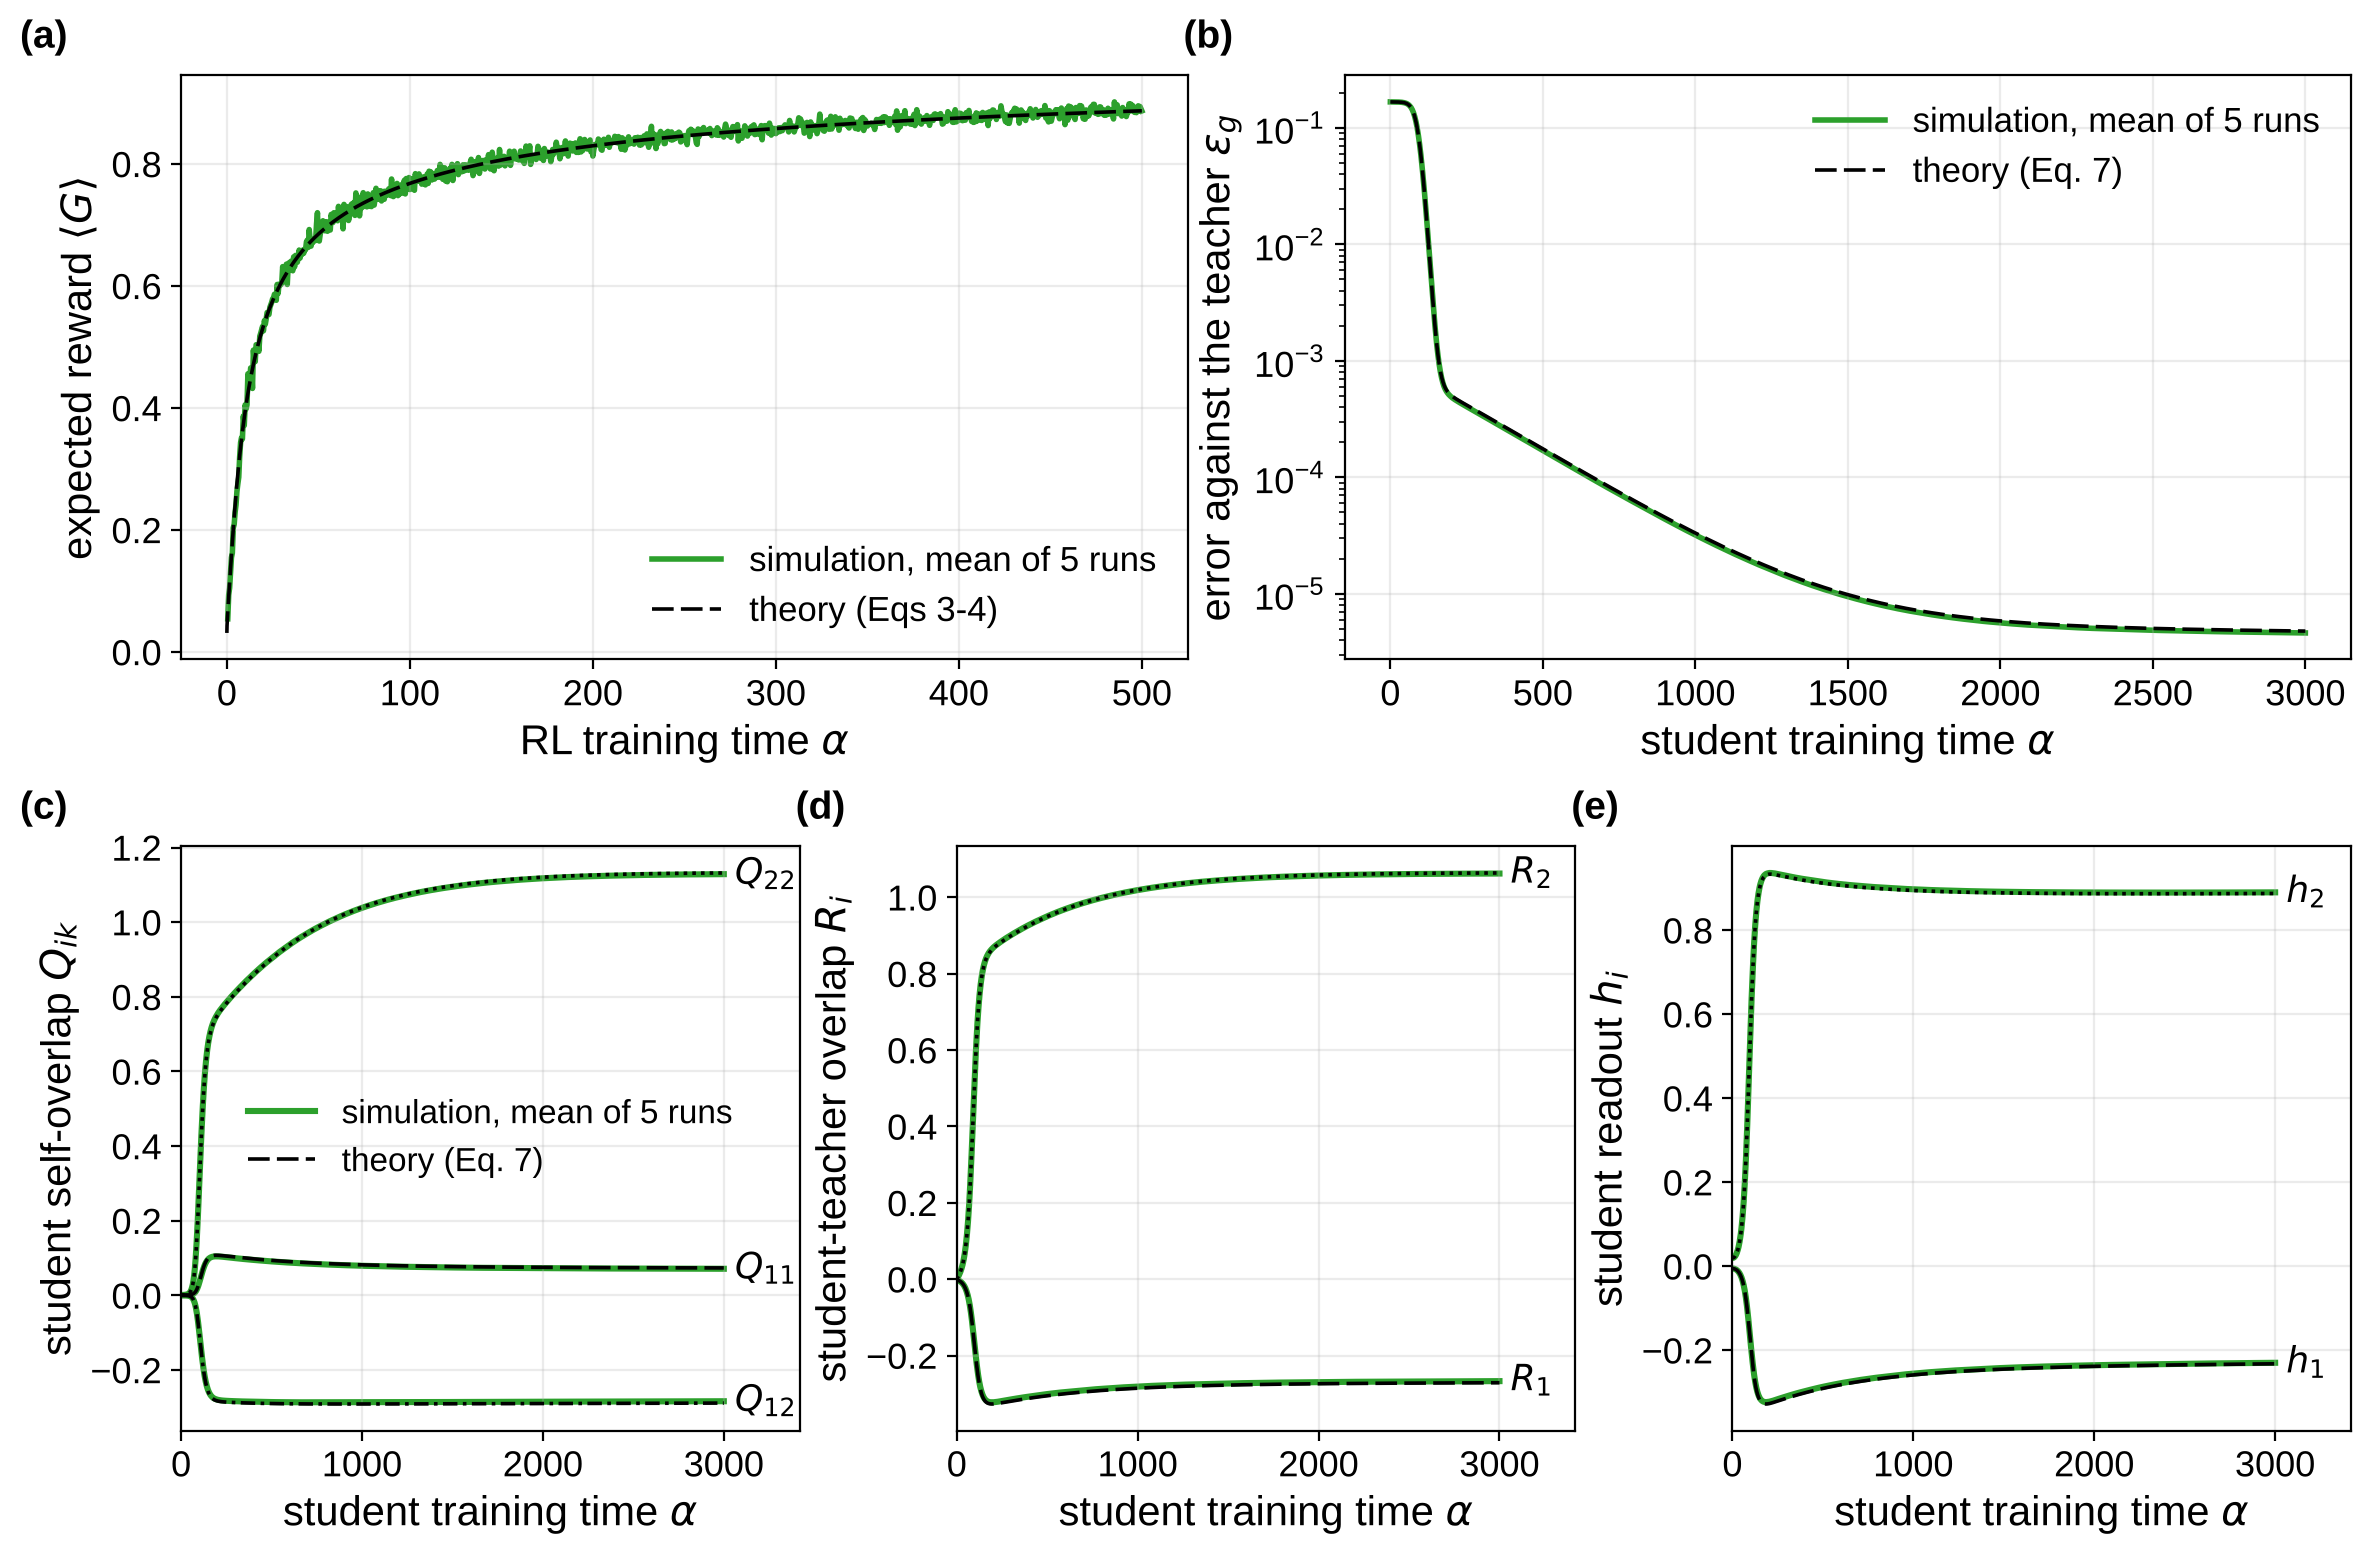

In [22]:
# Figure 1: both stages follow their theory
fig = plt.figure(figsize=(14, 8.8))
grid = fig.add_gridspec(2, 6, wspace=0.68, hspace=0.32)
ax_a, ax_b = fig.add_subplot(grid[0, :3]), fig.add_subplot(grid[0, 3:])
ax_c, ax_d, ax_e = (fig.add_subplot(grid[1, 2 * i:2 * i + 2]) for i in range(3))
simulation = dict(color=GREEN, zorder=1, label=f"simulation, mean of {N_RUNS} runs")

ax_a.plot(alpha1, np.mean([run["reward"] for run in stage1], axis=0), lw=2, **simulation)
ax_a.plot(alpha_ode, reward_ode, ls=DASHES[0], label="theory (Eqs 3-4)", **THEORY)
ax_a.set(xlabel=r"RL training time $\alpha$", ylabel=r"expected reward $\langle G\rangle$")
ax_a.legend(loc="lower right")

ax_b.plot(alpha2, eps2, lw=2, **simulation)
ax_b.plot(ode2["alpha"][::10], eps2_ode, ls=DASHES[0], label="theory (Eq. 7)", **THEORY)
ax_b.set(yscale="log", xlabel=r"student training time $\alpha$",
         ylabel=r"error against the teacher $\epsilon_g$")
ax_b.legend()

panels = [(ax_c, "Q", r"student self-overlap $Q_{ik}$",
           {"$Q_{11}$": (0, 0), "$Q_{22}$": (1, 1), "$Q_{12}$": (0, 1)}),
          (ax_d, "R", r"student-teacher overlap $R_i$", {"$R_1$": 0, "$R_2$": 1}),
          (ax_e, "h", r"student readout $h_i$", {"$h_1$": 0, "$h_2$": 1})]
for ax, key, ylabel, curves in panels:
    for (name, index), dash in zip(curves.items(), DASHES):
        sim, ode = mean2[key].T[index], ode2[key].T[index]
        ax.plot(alpha2, sim, lw=2.2, **simulation)
        ax.plot(ode2["alpha"], ode, ls=dash, **THEORY)
        ax.annotate(name, (alpha2[-1], sim[-1]), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=13)
    ax.set(xlabel=r"student training time $\alpha$", ylabel=ylabel, xlim=(0, 1.14 * alpha2[-1]))
ax_c.legend(handles=[Line2D([], [], color=GREEN, lw=2.2, label=simulation["label"]),
                     Line2D([], [], ls=DASHES[0], color="black", lw=1.3, label="theory (Eq. 7)")],
            loc="center", fontsize=12)

label_panels([ax_a, ax_b, ax_c, ax_d, ax_e])
fig.savefig(FIGURES / "Figure1.pdf")
plt.show()

**What it shows.** Both stages follow their equations: the RL perceptron's reward (a), and the student's error against the teacher (b) and order parameters (c)–(e). By the end the student is an almost perfect copy of its teacher.

## 3. Sweep — teacher quality

Every stage-1 run kept eight frozen copies of its perceptron, from untrained to fully trained. Each copy teaches a new student for $\alpha = 300$, which gives 40 students. The theory for each student takes the teacher's quality $\rho$ from equation (4), so it uses equations only.

In [23]:
def by_teacher(values):
    """Reshape a list over all students into an array (run, teacher)."""
    return np.reshape(values, (N_RUNS, len(FREEZE_RHOS)))


# every frozen copy teaches one student; the students of a run share their start and their inputs
students = []
for run, rl_run in enumerate(perceptrons):
    teachers = np.array([rescale(rl_run.frozen[n]) for n in FREEZE_EPISODES])
    sim = train_students(teachers, rl_run.w_star, ALPHA_SWEEP * D,
                         student_seed=1000 + run, data_seed=2000 + run)
    for j, teacher in enumerate(teachers):
        student = dict(student_path(sim, j), run=run, j=j, V=teacher @ rl_run.w_star / D,
                       teacher=teacher, W=sim["W"][j], H=sim["H"][j])
        student["eps_teacher"], student["eps_rule"] = errors(student)
        students.append(student)
first_run = [s for s in students if s["run"] == 0]

print("quality rho of the frozen teachers, measured (one row per run):")
print(by_teacher([s["V"] for s in students]).round(3))

quality rho of the frozen teachers, measured (one row per run):
[[0.059 0.22  0.458 0.629 0.799 0.901 0.95  0.997]
 [0.041 0.228 0.432 0.622 0.816 0.912 0.955 0.997]
 [0.02  0.198 0.403 0.586 0.783 0.893 0.95  0.997]
 [0.027 0.177 0.408 0.613 0.806 0.9   0.949 0.997]
 [0.014 0.2   0.411 0.587 0.79  0.9   0.949 0.997]]


In [24]:
def sweep_theory(student, v):
    """Equation (7) from the student's own initial overlaps, for teacher quality v."""
    ode = student_ode(student["Q"][0], student["R"][0], student["U"][0], student["h"][0],
                      v, ALPHA_SWEEP, n_steps=1000)
    ode = {key: values[::10] for key, values in ode.items()}
    ode["eps_teacher"], ode["eps_rule"] = errors(ode)
    return ode


# rho from equation (4) goes into equation (7)
for s in students:
    s["theory"] = sweep_theory(s, FREEZE_RHOS[s["j"]])

# for the curves of the first run: the theory with the rho each teacher actually reached
for s in first_run:
    s["theory_measured"] = sweep_theory(s, s["V"])

### Check 9 — every teacher is copied equally well

In [25]:
# check: the student copies every teacher equally well, whatever the teacher's quality
eps_teacher = by_teacher([s["eps_teacher"][-1] for s in students])
eps_teacher_theory = by_teacher([s["theory"]["eps_teacher"][-1] for s in students])
mean_eps, mean_theory = eps_teacher.mean(axis=0), eps_teacher_theory.mean(axis=0)
print(f"error against the teacher after alpha = {ALPHA_SWEEP}:")
print(f"  mean of {N_RUNS} runs  {mean_eps.min():.1e} to {mean_eps.max():.1e} over the teachers, "
      f"within {np.abs(mean_eps / mean_theory - 1).max():.1%} of the theory")
print(f"  single students  {eps_teacher.min():.0e} to {eps_teacher.max():.0e}, "
      f"median distance from the theory {np.median(np.abs(eps_teacher / eps_teacher_theory - 1)):.1%}")

results["error against the teacher after the sweep"] = f"{mean_eps.min():.1e} to {mean_eps.max():.1e}"

error against the teacher after alpha = 300:
  mean of 5 runs  6.7e-04 to 7.7e-04 over the teachers, within 0.7% of the theory
  single students  4e-05 to 1e-03, median distance from the theory 0.6%


### Figure 2 — only the teacher's quality passes

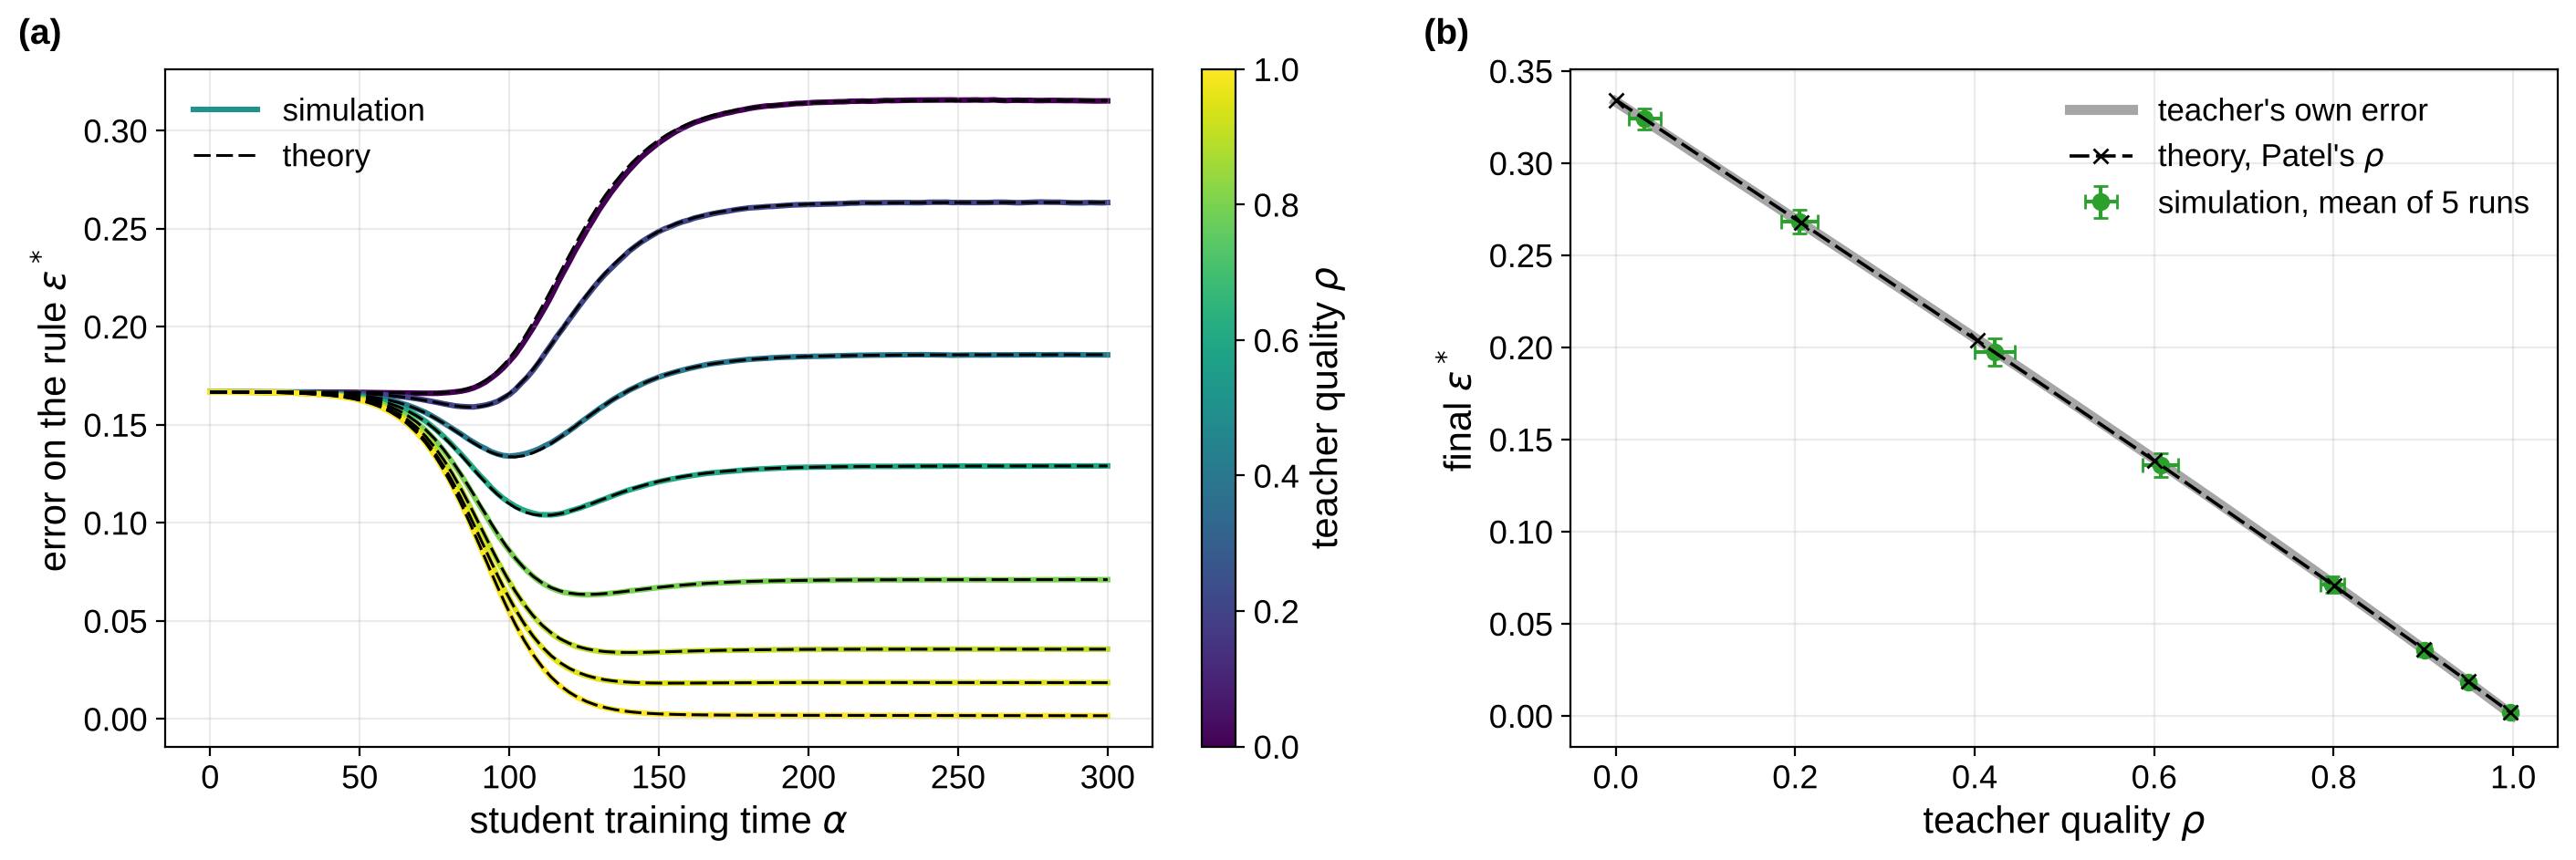

alpha_RL  rho (Eq. 4)  rho measured       error on the rule: simulation   theory   teacher's own
    0.00  0.0000       0.0324 ± 0.0179    0.3239 ± 0.0059                 0.3342   0.3333
    0.35  0.2064       0.2047 ± 0.0199    0.2681 ± 0.0065                 0.2676   0.2675
    1.23  0.4028       0.4225 ± 0.0225    0.1972 ± 0.0075                 0.2037   0.2042
    2.85  0.6007       0.6072 ± 0.0199    0.1361 ± 0.0066                 0.1383   0.1391
    6.88  0.8003       0.7988 ± 0.0131    0.0712 ± 0.0045                 0.0706   0.0712
   13.78  0.9001       0.9012 ± 0.0069    0.0357 ± 0.0024                 0.0360   0.0361
   26.68  0.9500       0.9505 ± 0.0026    0.0183 ± 0.0009                 0.0185   0.0182
  500.00  0.9972       0.9973 ± 0.0001    0.0017 ± 0.0004                 0.0017   0.0010


In [26]:
# Figure 2: the student's error on the rule is its teacher's own error
V, V_sd = mean_sd(by_teacher([s["V"] for s in students]))
eps_rule, eps_rule_sd = mean_sd(by_teacher([s["eps_rule"][-1] for s in students]))
eps_rule_theory = by_teacher([s["theory"]["eps_rule"][-1] for s in students]).mean(axis=0)

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 4.6), layout="constrained", gridspec_kw=dict(wspace=0.06))

for s in first_run:
    ax_a.plot(s["alpha"], s["eps_rule"], color=rho_colour(FREEZE_RHOS[s["j"]]), lw=2.2, zorder=1)
    ax_a.plot(s["theory_measured"]["alpha"], s["theory_measured"]["eps_rule"], ls=DASHES[0],
              color="black", lw=1.1, zorder=3)
ax_a.set(xlabel=r"student training time $\alpha$", ylabel=r"error on the rule $\epsilon^*$")
ax_a.legend(handles=[Line2D([], [], color=rho_colour(0.5), lw=2.2, label="simulation"),
                     Line2D([], [], ls=DASHES[0], color="black", lw=1.1, label="theory")],
            loc="upper left")
rho_colourbar(fig, ax_a)

rho_grid = np.linspace(0, 1, 200)
ax_b.plot(rho_grid, teacher_error(rho_grid), color="0.65", lw=4, zorder=0, label="teacher's own error")
ax_b.plot(FREEZE_RHOS, eps_rule_theory, ls=DASHES[0], marker="x", label=r"theory, Patel's $\rho$", **THEORY)
ax_b.errorbar(V, eps_rule, xerr=V_sd, yerr=eps_rule_sd, fmt="o", color=GREEN, ms=6, capsize=3,
              zorder=2, label=f"simulation, mean of {N_RUNS} runs")
ax_b.set(xlabel=r"teacher quality $\rho$", ylabel=r"final $\epsilon^*$")
ax_b.legend()

label_panels([ax_a, ax_b])
fig.savefig(FIGURES / "Figure2.pdf")
plt.show()

print("alpha_RL  rho (Eq. 4)  rho measured       error on the rule: simulation   theory   teacher's own")
for j in range(len(FREEZE_RHOS)):
    print(f"{FREEZE_ALPHAS[j]:8.2f}  {FREEZE_RHOS[j]:.4f}       {V[j]:.4f} ± {V_sd[j]:.4f}    "
          f"{eps_rule[j]:.4f} ± {eps_rule_sd[j]:.4f}                 {eps_rule_theory[j]:.4f}   "
          f"{teacher_error(FREEZE_RHOS[j]):.4f}")

**What it shows.** The student's error on the rule settles at its teacher's own error, whatever the teacher's quality: the student learns its teacher, not the rule. The black theory in (b) uses equations only.

### Check 10 — why only $\rho$ passes: $U = \rho R$

The student's overlap with the rule stays locked to its overlap with the teacher (appendix B of the report).

In [27]:
# U = rho R: exact in the equations when it holds at the start, and close in the simulations
s = students[-1]
exact = student_ode(s["Q"][0], s["R"][0], s["V"] * s["R"][0], s["h"][0], s["V"], ALPHA_SWEEP, n_steps=1000)
print(f"equations:   largest |U - V R| = {np.abs(exact['U'] - s['V'] * exact['R']).max():.0e}")
gap = max(np.abs(s["U"][-1] - s["V"] * s["R"][-1]).max() for s in students)
size = np.mean([np.abs(s["R"][-1]).max() for s in students])
print(f"simulations: largest |U - V R| = {gap:.3f} over the {len(students)} students at the end "
      f"(typical |R| = {size:.2f})")

results["largest |U - V R|"] = (f"{np.abs(exact['U'] - s['V'] * exact['R']).max():.0e} (equations), "
                                f"{gap:.3f} (simulations)")

equations:   largest |U - V R| = 9e-16
simulations: largest |U - V R| = 0.001 over the 40 students at the end (typical |R| = 0.84)


## 4. The distilled student's expected reward

The student plays the RL task with the decision $\mathrm{sgn}\,\phi(x)$. Its expected reward is $P_s^T$, where $P_s$ is the probability of a correct decision. $P_s$ depends only on the overlaps, and is evaluated on a fixed sample of the Gaussian fields $(\lambda_1, \lambda_2, \nu, \nu^*)$ built with the covariance assembler.

In [28]:
FIELDS = np.random.default_rng(12345).normal(size=(200_000, K + 2))          # for the curves
FIELDS_BIG = np.random.default_rng(54321).normal(size=(2_000_000, K + 2))    # for the final values


def decisions(q, r, u, h, v, sample):
    """Decisions of the student, its teacher and the rule on fields with the covariance
    that the overlaps give."""
    C = covariance([*range(len(h)), TEACHER, RULE], q, r, u, v)
    eigenvalues, vectors = np.linalg.eigh(C)
    fields = sample @ (vectors * np.sqrt(np.clip(eigenvalues, 0, None))).T
    k = len(h)
    return np.sign(g(fields[:, :k]) @ h), np.sign(fields[:, k]), np.sign(fields[:, k + 1])


def reward_curve(path, v, sample=FIELDS):
    """The student's expected reward along a path of overlaps."""
    rewards = []
    for q, r, u, h in zip(path["Q"], path["R"], path["U"], path["h"]):
        y, _, y_rule = decisions(q, r, u, h, v, sample)
        rewards.append(np.mean(y == y_rule) ** T)
    return np.array(rewards)

### Check 11 — the teacher's decisions on the sampled fields

In [29]:
# check: on the sampled fields the teacher is right with probability 1 - arccos(rho) / pi, equation (2)
for s in first_run[2::2]:
    _, y_teacher, y_rule = decisions(s["Q"][-1], s["R"][-1], s["U"][-1], s["h"][-1], s["V"], FIELDS_BIG)
    print(f"rho = {s['V']:.4f}:  teacher right on {np.mean(y_teacher == y_rule):.4f} of the sample, "
          f"equation (2) gives {1 - np.arccos(s['V']) / np.pi:.4f}")

rho = 0.4577:  teacher right on 0.6512 of the sample, equation (2) gives 0.6513
rho = 0.7993:  teacher right on 0.7949 of the sample, equation (2) gives 0.7948
rho = 0.9499:  teacher right on 0.8989 of the sample, equation (2) gives 0.8988


### The reward of all 40 students

In [30]:
# every student at the end of its training, and the same from the equations alone
for s in students:
    y, y_teacher, y_rule = decisions(s["Q"][-1], s["R"][-1], s["U"][-1], s["h"][-1], s["V"], FIELDS_BIG)
    s["G_teacher"] = expected_reward_rl(s["V"])
    s["G_end"] = np.mean(y == y_rule) ** T
    s["G_gap"] = s["G_end"] - np.mean(y_teacher == y_rule) ** T      # both on the same sample
    s["agreement"] = np.mean(y == y_teacher)
    ode = s["theory"]
    y, _, y_rule = decisions(ode["Q"][-1], ode["R"][-1], ode["U"][-1], ode["h"][-1],
                             FREEZE_RHOS[s["j"]], FIELDS_BIG)
    s["G_end_theory"] = np.mean(y == y_rule) ** T

# the whole curve for the students of the first run

for s in first_run:
    s["G"] = reward_curve(s, s["V"])
    s["theory_measured"]["G"] = reward_curve(s["theory_measured"], s["V"])

### Check 12 — reward from overlaps against played episodes

In [31]:
# check: play real episodes with the trained students of the first run and their teachers
n_episodes, batch = 40_000, 2_000
rng = np.random.default_rng(99)
rewarded = np.zeros((2, len(first_run)))             # students, teachers
for _ in range(n_episodes // batch):
    X = rng.normal(size=(batch * T, D))
    y_rule = np.sign(X @ rl.w_star)
    for s in first_run:
        y_student = np.sign(g(X @ s["W"].T / np.sqrt(D)) @ s["H"])
        y_teacher = np.sign(X @ s["teacher"])
        for row, y in enumerate((y_student, y_teacher)):
            rewarded[row, s["j"]] += (y == y_rule).reshape(batch, T).all(axis=1).sum()

print(f"expected reward from the overlaps, and from {n_episodes:,} played episodes")
print("rho      student: overlaps  played    teacher: Eq. 3  played")
for s in first_run:
    played_student, played_teacher = rewarded[:, s["j"]] / n_episodes
    print(f"{s['V']:.4f}            {s['G_end']:.4f}  {played_student:.4f}"
          f"             {s['G_teacher']:.4f}  {played_teacher:.4f}")

expected reward from the overlaps, and from 40,000 played episodes
rho      student: overlaps  played    teacher: Eq. 3  played
0.0591            0.0375  0.0398             0.0376  0.0398
0.2195            0.0603  0.0592             0.0604  0.0592
0.4577            0.1172  0.1188             0.1172  0.1188
0.6287            0.1888  0.1872             0.1887  0.1873
0.7993            0.3174  0.3182             0.3172  0.3184
0.9015            0.4636  0.4641             0.4637  0.4641
0.9499            0.5869  0.5861             0.5866  0.5864
0.9973            0.8881  0.8858             0.8884  0.8864


### Check 13 — the student earns its teacher's reward

In [32]:
# the student's reward against its teacher's, for every teacher
G_teacher, G_student, G_theory = (by_teacher([s[key] for s in students]).mean(axis=0)
                                  for key in ("G_teacher", "G_end", "G_end_theory"))

print("alpha_RL  teacher's reward  student's reward   equations alone  student - teacher")
for j in range(len(FREEZE_RHOS)):
    G_runs = np.array([s["G_end"] for s in students if s["j"] == j])
    gap = np.mean([s["G_gap"] for s in students if s["j"] == j])
    print(f"{FREEZE_ALPHAS[j]:8.2f}  {G_teacher[j]:.4f}            {G_runs.mean():.4f} ± {G_runs.std(ddof=1):.4f}    "
          f"{G_theory[j]:.4f}           {gap:+.4f}")
agreement = [s["agreement"] for s in students]
print(f"student and teacher make the same decision on {min(agreement):.2%} to {max(agreement):.2%} of inputs")

gaps = [np.mean([s["G_gap"] for s in students if s["j"] == j]) for j in range(len(FREEZE_RHOS))]
results["student's reward minus its teacher's"] = f"within {np.abs(gaps).max():.4f}"
results["same decision as the teacher"] = f"{min(agreement):.2%} to {max(agreement):.2%} of inputs"

alpha_RL  teacher's reward  student's reward   equations alone  student - teacher
    0.00  0.0346            0.0346 ± 0.0019    0.0312           -0.0000
    0.35  0.0580            0.0579 ± 0.0033    0.0581           +0.0000
    1.23  0.1066            0.1065 ± 0.0068    0.1007           +0.0000
    2.85  0.1778            0.1777 ± 0.0100    0.1741           +0.0000
    6.88  0.3170            0.3170 ± 0.0138    0.3182           -0.0000
   13.78  0.4635            0.4638 ± 0.0140    0.4613           -0.0000
   26.68  0.5887            0.5892 ± 0.0089    0.5875           -0.0001
  500.00  0.8876            0.8873 ± 0.0008    0.8867           -0.0003
student and teacher make the same decision on 99.73% to 99.95% of inputs


### Figure 3 — the distilled student's expected reward

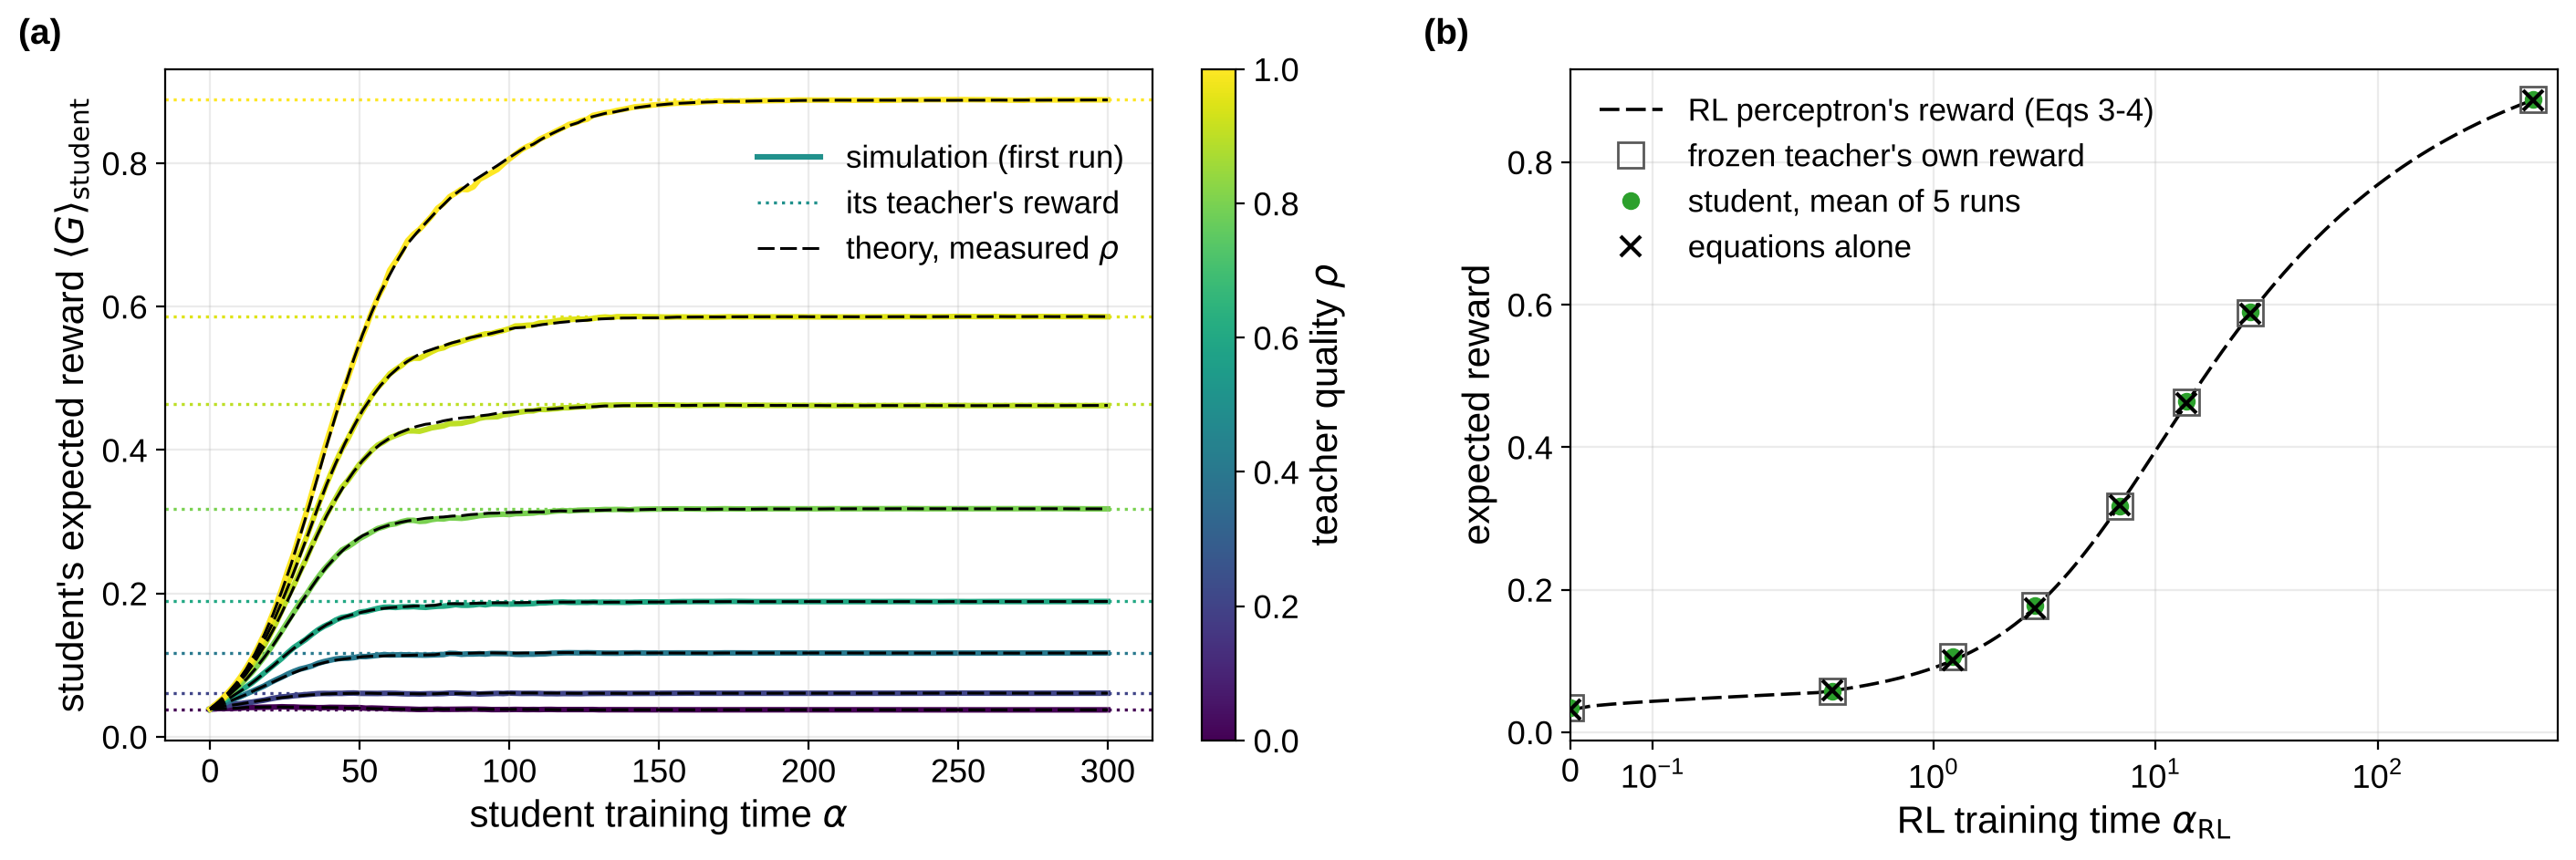


teacher with rho = 0.80: the student has 90% of its teacher's reward at alpha = 54,
when its error against the teacher is still 0.161; the error is below 0.01 from alpha = 126


In [33]:
# Figure 3: the student's reward is its teacher's
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 4.6), layout="constrained", gridspec_kw=dict(wspace=0.06))

for s in first_run:
    colour = rho_colour(FREEZE_RHOS[s["j"]])
    ax_a.axhline(s["G_teacher"], color=colour, ls=":", lw=1.2, zorder=0)
    ax_a.plot(s["alpha"], s["G"], color=colour, lw=2.2, zorder=1)
    ax_a.plot(s["theory_measured"]["alpha"], s["theory_measured"]["G"], ls=DASHES[0],
              color="black", lw=1.1, zorder=3)
ax_a.set(xlabel=r"student training time $\alpha$",
         ylabel=r"student's expected reward $\langle G\rangle_{\rm student}$")
ax_a.legend(handles=[Line2D([], [], color=rho_colour(0.5), lw=2.2, label="simulation (first run)"),
                     Line2D([], [], color=rho_colour(0.5), ls=":", lw=1.2, label="its teacher's reward"),
                     Line2D([], [], ls=DASHES[0], color="black", lw=1.1, label=r"theory, measured $\rho$")],
            loc="upper right", bbox_to_anchor=(1, 0.93))
rho_colourbar(fig, ax_a)

ax_b.plot(alpha_ode, reward_ode, ls=DASHES[0], color="black", lw=1.3,
          label="RL perceptron's reward (Eqs 3-4)")
ax_b.plot(FREEZE_ALPHAS, G_teacher, "s", mfc="none", mec="0.35", ms=10, zorder=2,
          label="frozen teacher's own reward")
ax_b.plot(FREEZE_ALPHAS, G_student, "o", color=GREEN, ms=6, zorder=3,
          label=f"student, mean of {N_RUNS} runs")
ax_b.plot(FREEZE_ALPHAS, G_theory, "x", color="black", ms=8, mew=1.5, zorder=4, label="equations alone")
ax_b.set_xscale("symlog", linthresh=0.3)
ax_b.set(xlim=(0, 1.3 * ALPHA_RL), xlabel=r"RL training time $\alpha_{\rm RL}$", ylabel="expected reward")
ax_b.legend(loc="upper left")

label_panels([ax_a, ax_b])
fig.savefig(FIGURES / "Figure3.pdf")
plt.show()

# the reward arrives before the squared error falls (teacher with rho = 0.80, first run)
s = first_run[4]
i = np.argmax(s["G"] >= 0.9 * s["G_teacher"])
i_low = np.argmax(s["eps_teacher"] < 0.01)
print(f"\nteacher with rho = {s['V']:.2f}: the student has 90% of its teacher's reward at alpha = {s['alpha'][i]:.0f},")
print(f"when its error against the teacher is still {s['eps_teacher'][i]:.3f}; "
      f"the error is below 0.01 from alpha = {s['alpha'][i_low]:.0f}")

**What it shows.** During training the reward climbs to the teacher's level and stops there (a). At the end the student's reward equals its teacher's at every $\alpha_{\rm RL}$, and the crosses show the same numbers from equations alone (b).

## 5. An equation for the student's reward

Near its decision boundary the student acts like one perceptron with weights $\sum_i h_i w_i$. With the copy quality $c = h^\top R/\sqrt{h^\top Q h}$ of equation (8) and $U=\rho R$, this gives equation (9):

$$\langle G\rangle_{\rm student}\approx\left[1-\frac{\arccos(\rho c)}{\pi}\right]^T .$$

In [34]:
def copy_quality(path):
    """c of equation (8) along a path of overlaps."""
    return np.array([h @ r / np.sqrt(h @ q @ h) for q, r, h in zip(path["Q"], path["R"], path["h"])])


def reward_equation(rho, c, T=T):
    """Equation (9)."""
    return (1 - np.arccos(np.clip(rho * c, -1, 1)) / np.pi) ** T


def first_crossing(x, y, level):
    """Where y first reaches level, by linear interpolation."""
    i = np.argmax(y >= level)
    return x[i - 1] + (level - y[i - 1]) * (x[i] - x[i - 1]) / (y[i] - y[i - 1])


def reward_share(s, c_level, T_other=T):
    """The student's exact reward as a share of its teacher's at the time its c reaches
    c_level, if episodes had length T_other."""
    P_student = np.interp(first_crossing(s["alpha"], s["c"], c_level), s["alpha"], s["G"] ** (1 / T))
    return (P_student / (1 - np.arccos(s["V"]) / np.pi)) ** T_other


for s in first_run:
    s["c"] = copy_quality(s)
    s["theory_measured"]["c"] = copy_quality(s["theory_measured"])
    # quality of the effective perceptron, measured directly: cosine between sum_i h_i w_i and w*
    s["rho_s"] = np.array([h @ u / np.sqrt(h @ q @ h) for q, u, h in zip(s["Q"], s["U"], s["h"])])

### Check 14 — equation (9) against the exact reward

The last two lines check the two steps of its derivation (appendix D of the report) separately.

In [35]:
# check: equation (9) against the exact reward
gap_training = max(np.abs(reward_equation(s["V"], s["c"]) - s["G"]).max() for s in first_run)
gap_end = max(abs(reward_equation(s["V"], copy_quality(s)[-1]) - s["G_end"]) for s in students)
gap_equations = max(abs(reward_equation(FREEZE_RHOS[s["j"]], copy_quality(s["theory"])[-1]) - s["G_end_theory"])
                    for s in students)
print("equation (9) against the exact reward")
print(f"  during training, first run:  {gap_training:.4f}")
print(f"  at the end, all {len(students)} students: {gap_end:.4f}")
print(f"  equations alone (rho from Eq. 4, c from Eq. 7) against the full theory: {gap_equations:.4f}")

# the two steps of its derivation (appendix D)
late = first_run[0]["alpha"] >= 100
gap_step1 = max(np.abs(reward_equation(s["rho_s"], 1) - s["G"]).max() for s in first_run)
gap_step3 = np.array([np.abs(s["rho_s"] - s["V"] * s["c"]) for s in first_run])
print("steps of the derivation, first run")
print(f"  one perceptron with the measured rho_s against the exact reward: {gap_step1:.4f}")
print(f"  rho_s against rho c: {gap_step3.max():.3f} over the whole run, {gap_step3[:, late].max():.3f} from alpha = 100")

results["equation (9) against the exact reward"] = f"{gap_training:.3f} (training), {gap_end:.4f} (end)"
results["equation (9) from equations alone against the full theory"] = f"{gap_equations:.4f}"

equation (9) against the exact reward
  during training, first run:  0.0110
  at the end, all 40 students: 0.0008
  equations alone (rho from Eq. 4, c from Eq. 7) against the full theory: 0.0009
steps of the derivation, first run
  one perceptron with the measured rho_s against the exact reward: 0.0042
  rho_s against rho c: 0.075 over the whole run, 0.004 from alpha = 100


In [36]:
# the copy quality grows at about the same rate for every teacher
for level in (0.95, 0.99):
    times = [first_crossing(s["alpha"], s["c"], level) for s in first_run]
    print(f"c reaches {level} at alpha = {min(times):.0f} to {max(times):.0f}")

c reaches 0.95 at alpha = 52 to 56
c reaches 0.99 at alpha = 87 to 91


### Figure 4 — one number sets the reward

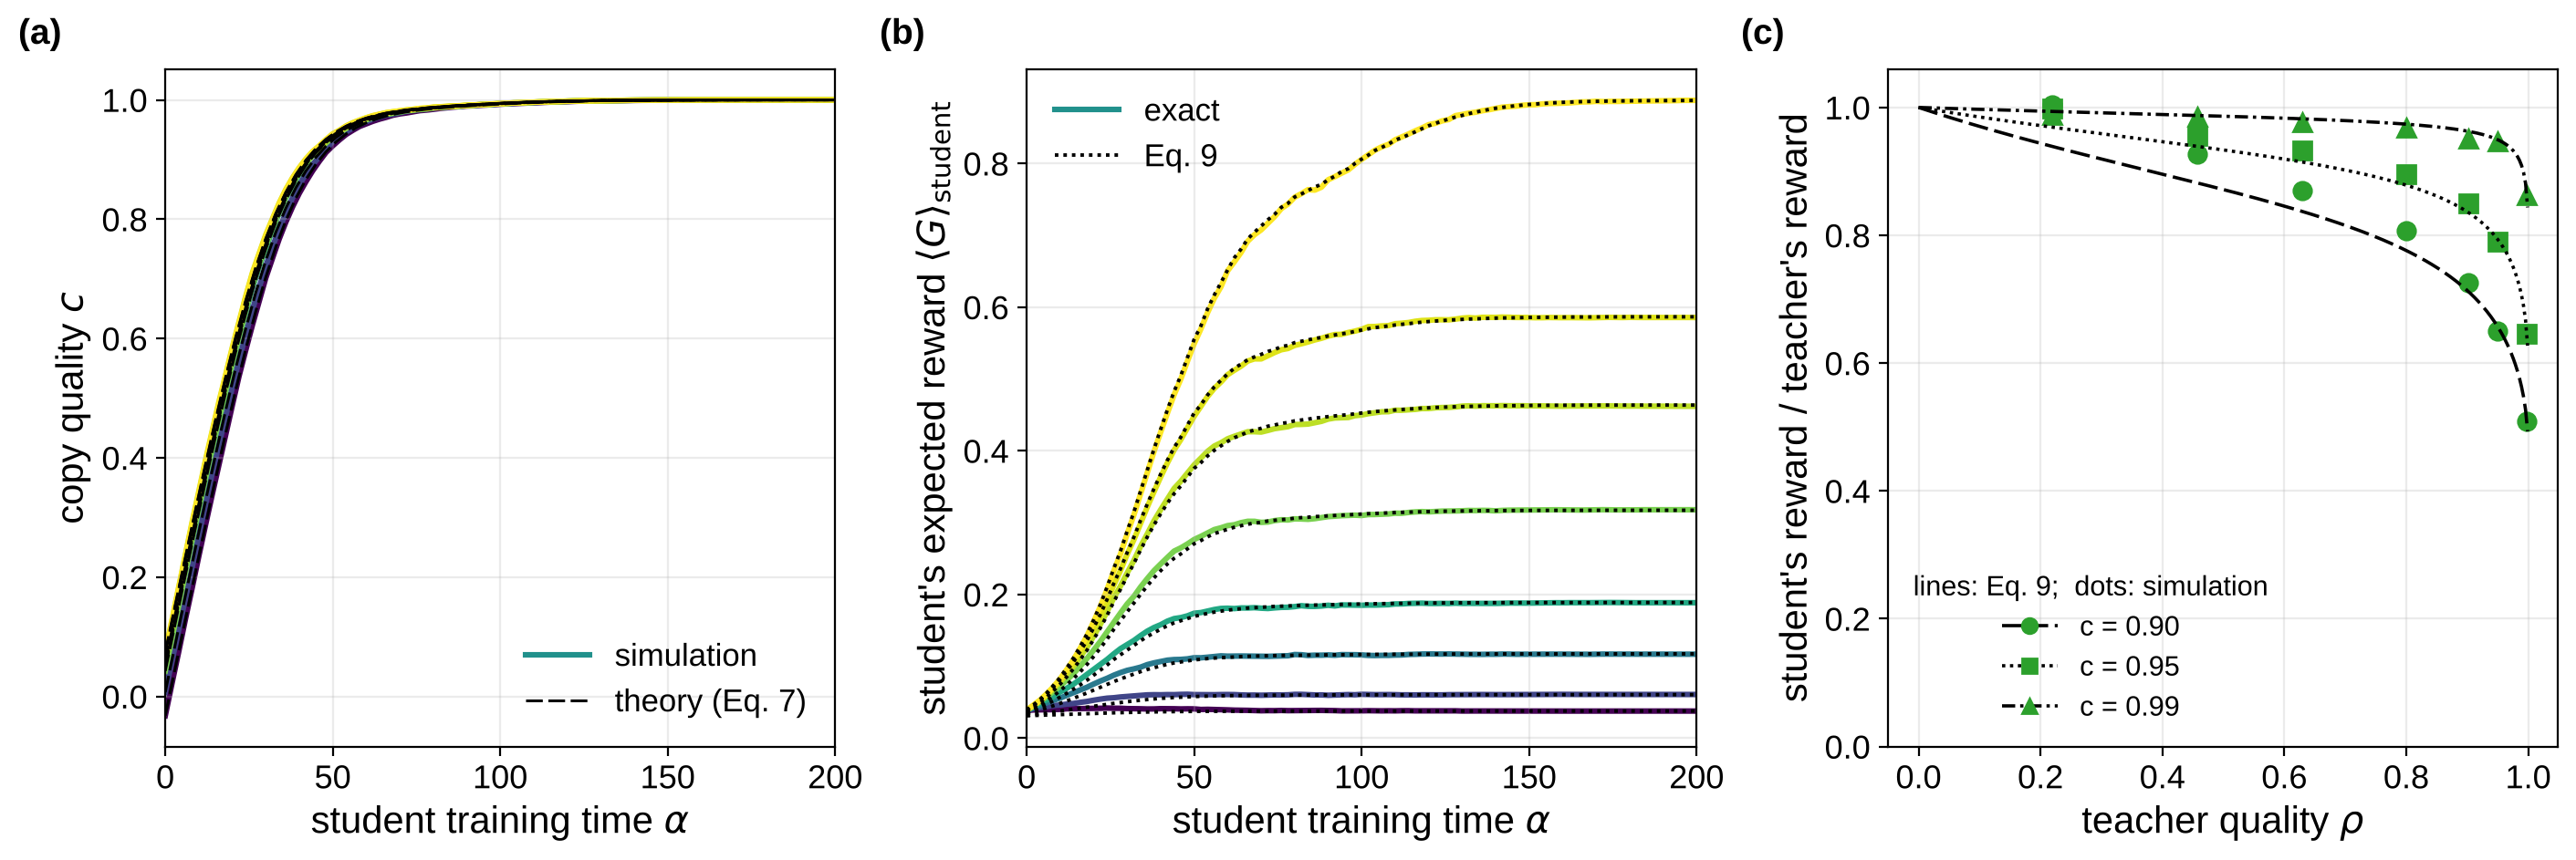

In [37]:
# Figure 4: the reward equation
fig, (ax_a, ax_b, ax_c) = plt.subplots(1, 3, figsize=(14, 4.6), layout="constrained")

for s in first_run:
    colour = rho_colour(FREEZE_RHOS[s["j"]])
    ax_a.plot(s["alpha"], s["c"], color=colour, lw=2.2, zorder=1)
    ax_a.plot(s["theory_measured"]["alpha"], s["theory_measured"]["c"], ls=DASHES[0],
              color="black", lw=1.1, zorder=3)
    ax_b.plot(s["alpha"], s["G"], color=colour, lw=2.2, zorder=1)
    ax_b.plot(s["alpha"], reward_equation(s["V"], s["c"]), ls=DASHES[1], color="black", lw=1.4, zorder=3)
ax_a.set(xlim=(0, 200), xlabel=r"student training time $\alpha$", ylabel=r"copy quality $c$")
ax_a.legend(handles=[Line2D([], [], color=rho_colour(0.5), lw=2.2, label="simulation"),
                     Line2D([], [], ls=DASHES[0], color="black", lw=1.1, label="theory (Eq. 7)")],
            loc="lower right")
ax_b.set(xlim=(0, 200), xlabel=r"student training time $\alpha$",
         ylabel=r"student's expected reward $\langle G\rangle_{\rm student}$")
ax_b.legend(handles=[Line2D([], [], color=rho_colour(0.5), lw=2.2, label="exact"),
                     Line2D([], [], ls=DASHES[1], color="black", lw=1.4, label="Eq. 9")],
            loc="upper left")

rho_grid = np.linspace(0, 0.999, 300)
handles = []
for c_level, dash, marker in zip((0.90, 0.95, 0.99), DASHES, "os^"):
    ax_c.plot(rho_grid, reward_equation(rho_grid, c_level) / reward_equation(rho_grid, 1), ls=dash, **THEORY)
    # the teacher frozen at alpha_RL = 0 is left out: its reward is at chance level
    ax_c.plot([s["V"] for s in first_run[1:]], [reward_share(s, c_level) for s in first_run[1:]],
              marker, color=GREEN, ms=7, zorder=2)
    handles.append(Line2D([], [], ls=dash, color="black", lw=1.3, marker=marker, mfc=GREEN, mec=GREEN,
                          label=f"c = {c_level:.2f}"))
ax_c.set(ylim=(0, 1.06), xlabel=r"teacher quality $\rho$", ylabel="student's reward / teacher's reward")
ax_c.legend(handles=handles, loc="lower left", fontsize=11, title="lines: Eq. 9;  dots: simulation",
            title_fontsize=11)

label_panels([ax_a, ax_b, ax_c])
fig.savefig(FIGURES / "Figure4.pdf")
plt.show()

**What it shows.** The copy quality $c$ grows at about the same rate for every teacher (a), and equation (9) turns it into the reward (b). The same copy error costs more reward when the teacher is better (c).

### What the equation says

In [38]:
# the same copying error costs more reward when the teacher is better and when episodes are longer
print("when c = 0.95 (first run)")
for s in (first_run[3], first_run[6], first_run[7]):
    wrong_teacher = np.arccos(s["V"]) / np.pi
    wrong_student = 1 - (1 - wrong_teacher) * reward_share(s, 0.95, T_other=1)
    print(f"  rho = {s['V']:.3f}: the student has {reward_share(s, 0.95):.0%} of its teacher's reward "
          f"(Eq. 9: {reward_equation(s['V'], 0.95) / s['G_teacher']:.0%}); "
          f"wrong decisions {wrong_teacher:.1%} for the teacher, {wrong_student:.1%} for the student")
s = first_run[7]
print("  final teacher, other episode lengths: "
      + ", ".join(f"T = {T_other}: {reward_share(s, 0.95, T_other):.0%}" for T_other in (1, 5, 12)))

results["reward share at c = 0.95 for rho = 0.63, 0.95, 0.997"] = ", ".join(
    f"{reward_share(s, 0.95):.0%}" for s in (first_run[3], first_run[6], first_run[7]))
results["the same for the final teacher with T = 1, 5, 12"] = ", ".join(
    f"{reward_share(first_run[7], 0.95, T_other):.0%}" for T_other in (1, 5, 12))

when c = 0.95 (first run)
  rho = 0.629: the student has 93% of its teacher's reward (Eq. 9: 91%); wrong decisions 28.4% for the teacher, 29.4% for the student
  rho = 0.950: the student has 79% of its teacher's reward (Eq. 9: 79%); wrong decisions 10.1% for the teacher, 14.3% for the student
  rho = 0.997: the student has 65% of its teacher's reward (Eq. 9: 65%); wrong decisions 2.3% for the teacher, 10.5% for the student
  final teacher, other episode lengths: T = 1: 92%, T = 5: 65%, T = 12: 35%


## 6. Sweep 2 — episode length

The sweep is repeated with RL perceptrons trained with $T = 1$, 5 and 12 (three runs each).

In [39]:
# the final error on the rule that equation (7) predicts as a function of rho alone
w0, h0 = init_student(1000)
rng = np.random.default_rng(7)
a = rng.normal(size=D)
a *= np.sqrt(D) / np.linalg.norm(a)
b = rng.normal(size=D)
b -= (b @ a) / D * a
b *= np.sqrt(D) / np.linalg.norm(b)
v_grid = np.linspace(0, 1, 11)
eps_grid = []
for v in v_grid:
    rule = v * a + np.sqrt(1 - v ** 2) * b              # a rule that has overlap v with the teacher a
    ode = student_ode(w0 @ w0.T / D, w0 @ a / D, w0 @ rule / D, h0, v, ALPHA_SWEEP, n_steps=1000)
    eps_grid.append(squared_error(ode["Q"][-1], ode["h"][-1], ode["U"][-1]))

### Check 15 — the student only feels $
ho$

In [40]:
# RL perceptrons trained with other episode lengths, frozen at the same qualities, each teaching a student
largest = {}
for T_other in (1, 5, 12):
    alpha_T, R_T, Q_T = rl_ode(T_other, 120, n_steps=24000)
    rho_T = R_T / np.sqrt(Q_T)
    freeze_alphas = np.array([0.0] + [alpha_T[np.argmax(rho_T >= rho)] for rho in SWEEP_RHOS])
    freeze = np.round(freeze_alphas * D).astype(int)
    gaps = []
    for run in range(3):
        rl_T = RLPerceptron(D, T_other, seed=run)
        rl_T.train(freeze[-1], freeze_at=freeze)
        teachers = np.array([rescale(rl_T.frozen[n]) for n in freeze])
        sim = train_students(teachers, rl_T.w_star, ALPHA_SWEEP * D,
                             student_seed=1000 + run, data_seed=2000 + run)
        eps = [squared_error(sim["Q"][-1, j], sim["h"][-1, j], sim["U"][-1, j]) for j in range(len(teachers))]
        gaps.append(eps - np.interp(teachers @ rl_T.w_star / D, v_grid, eps_grid))
    largest[T_other] = np.abs(gaps).max()
    print(f"T = {T_other:2d}: final error on the rule within {largest[T_other]:.4f} of the prediction from rho")

results["other episode lengths: error on the rule against the prediction"] = f"within {max(largest.values()):.4f}"

T =  1: final error on the rule within 0.0003 of the prediction from rho


T =  5: final error on the rule within 0.0003 of the prediction from rho


T = 12: final error on the rule within 0.0003 of the prediction from rho


## 7. Summary

The numbers collected above, next to the values quoted in the report.

In [41]:
report = {
    "quality rho of the final RL perceptron": "0.9973 ± 0.0001",
    "its probability of a wrong decision": "0.0236 ± 0.0003 (theory 0.0237)",
    "its expected reward": "0.887 ± 0.008 (theory 0.887)",
    "Q_RL and R_RL against equation (4)": "less than 0.2%",
    "student's error against the teacher at alpha = 3000": "(4.6 ± 0.2)e-6 (theory 4.8e-6)",
    "largest gap between stage-2 simulation and theory": "0.005 (mean of runs), 0.014 (one run)",
    "error against the teacher after the sweep": "6.7e-04 to 7.7e-04",
    "largest |U - V R|": "1e-15 (equations), 0.001 (simulations)",
    "student's reward minus its teacher's": "within 0.0003",
    "same decision as the teacher": "99.73% to 99.95% of inputs",
    "equation (9) against the exact reward": "0.011 (training), 0.0008 (end)",
    "equation (9) from equations alone against the full theory": "0.0009",
    "reward share at c = 0.95 for rho = 0.63, 0.95, 0.997": "93%, 79%, 65%",
    "the same for the final teacher with T = 1, 5, 12": "92%, 65%, 35%",
    "other episode lengths: error on the rule against the prediction": "within 0.0003",
}
width = max(len(value) for value in results.values())
print(f"{'':66s}{'this notebook':{width}s}   report")
for name, value in results.items():
    print(f"{name:66s}{value:{width}s}   {report[name]}")

                                                                  this notebook                            report
quality rho of the final RL perceptron                            0.9973 ± 0.0001                          0.9973 ± 0.0001
its probability of a wrong decision                               0.0236 ± 0.0003 (theory 0.0237)          0.0236 ± 0.0003 (theory 0.0237)
its expected reward                                               0.887 ± 0.008 (theory 0.887)             0.887 ± 0.008 (theory 0.887)
Q_RL and R_RL against equation (4)                                within 0.11%                             less than 0.2%
student's error against the teacher at alpha = 3000               (4.6 ± 0.2)e-6 (theory 4.8e-6)           (4.6 ± 0.2)e-6 (theory 4.8e-6)
largest gap between stage-2 simulation and theory                 0.005 (mean of runs), 0.014 (one run)    0.005 (mean of runs), 0.014 (one run)
error against the teacher after the sweep                         6.7e-04 to 7.7e-0